# Customer concept drift in SynCCFD

This notebook shows the customer concept drift of SynCCFD. Each customer has a
**regime A** (the original profile); a customer with drift also gets a **regime B**,
drawn from A, and a drift type that sets the weight of B over time, $w(t) \in [0, 1]$:

| type | $w(t)$ | how it applies |
|---|---|---|
| sudden | 0 before $t_0$, 1 after | parameters of B from $t_0$ on |
| gradual | rises from 0 to 1 over $[t_0, t_0 + L]$ | each transaction comes from B with probability $w(t)$ |
| incremental | same | interpolated parameters: $\theta(t) = (1 - w)\,\theta_A + w\,\theta_B$ |
| recurrent | 1 for $D$ days every $P$ days, from $t_0$ | e.g. holidays, travel |

`LANG` is the language of the figure labels: `"en"` (default) or `"pt"`; the environment
variable `SYNCCFD_LANG` sets it. The figures are saved as PDF in `figures/drift/`
(`SYNCCFD_FIG_DIR` changes `figures/`).

In [1]:
import os
import re
from pathlib import Path

# Fixed creation date in the PDF files: an unchanged figure is written byte for byte
# the same
os.environ.setdefault("SOURCE_DATE_EPOCH", "0")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import ticker

from synccfd import DatasetGenerator
from synccfd.simulator import presets
from synccfd.simulator.config import MerchantConfig
from synccfd.simulator.engine.drift import CustomerDrift, regime_weight

# Language of the figure labels: "en" or "pt"
LANG = os.environ.get("SYNCCFD_LANG", "en")
TEXT = {
    "en": {
        "types": {"sudden": "sudden", "gradual": "gradual", "incremental": "incremental", "recurrent": "recurrent"},
        "regime_tx": "regime {regime} transaction",
        "regime_mean": "mean amount observed in {regime}",
        "amount": "amount (R$)",
        "amount_title": "{kind}, customer {customer}: amount",
        "tx_per_day_bar": "transactions on the day",
        "rolling_mean": "moving average (14 days)",
        "expected_rate": r"expected rate $\lambda(t)$",
        "tx_per_day": "transactions per day",
        "frequency_title": "{kind}, customer {customer}: frequency",
        "day": "day",
        "marks_note": "Vertical line: $t_0$. Grey band: transition $[t_0, t_0+L]$. "
                      "Orange bands: episodes of regime B (recurrent).",
        "all_customers": "all customers",
        "mean_weight": r"mean weight of regime B, $\bar w(t)$",
        "log_spending": r"$\ln(g_B / g_A)$: spending factor",
        "log_amount": r"$\ln(\mu_B / \mu_A)$: mean amount",
        "log_frequency": r"$\ln(\lambda_B / \lambda_A)$: frequency",
        "cnp_change": r"$p_B - p_A$: CNP probability",
        "customers": "customers",
        "regime_a": "regime A",
        "regime_b": "regime B",
        "share_of_purchases": "% of the customer's purchases in the regime",
        "category_title": "{kind}, customer {customer}: purchases by category",
        "configured": "configured (ground truth)",
        "observed": "observed in the purchases",
        "tvd": "total variation distance between A and B",
        "drifting_customers": "customers with drift",
        "preference_change": "change of preference by category",
        # Values of the data, shown translated in the English figures
        "categories": {
            "supermercado": "supermarket", "restaurante_bar": "restaurant and bar",
            "posto_combustivel": "fuel station", "farmacia": "pharmacy",
            "vestuario": "clothing", "eletronicos": "electronics",
            "viagem_turismo": "travel", "ecommerce_marketplace": "marketplace",
            "servicos_digitais": "digital services", "transporte_app": "ride-hailing",
        },
    },
    "pt": {
        "types": {"sudden": "súbito", "gradual": "gradual", "incremental": "incremental", "recurrent": "recorrente"},
        "regime_tx": "transação do regime {regime}",
        "regime_mean": "valor médio observado em {regime}",
        "amount": "valor (R$)",
        "amount_title": "{kind}, cliente {customer}: valor",
        "tx_per_day_bar": "transações no dia",
        "rolling_mean": "média móvel (14 dias)",
        "expected_rate": r"taxa esperada $\lambda(t)$",
        "tx_per_day": "transações por dia",
        "frequency_title": "{kind}, cliente {customer}: frequência",
        "day": "dia",
        "marks_note": "Linha vertical: $t_0$. Faixa cinza: transição $[t_0, t_0+L]$. "
                      "Faixas laranja: episódios do regime B (recorrente).",
        "all_customers": "todos os clientes",
        "mean_weight": r"peso médio do regime B, $\bar w(t)$",
        "log_spending": r"$\ln(g_B / g_A)$: fator de gasto",
        "log_amount": r"$\ln(\mu_B / \mu_A)$: valor médio",
        "log_frequency": r"$\ln(\lambda_B / \lambda_A)$: frequência",
        "cnp_change": r"$p_B - p_A$: probabilidade de CNP",
        "customers": "clientes",
        "regime_a": "regime A",
        "regime_b": "regime B",
        "share_of_purchases": "% das compras do cliente no regime",
        "category_title": "{kind}, cliente {customer}: compras por categoria",
        "configured": "configurada (gabarito)",
        "observed": "observada nas compras",
        "tvd": "distância de variação total entre A e B",
        "drifting_customers": "clientes com drift",
        "preference_change": "mudança de preferência por categoria",
        "categories": {},  # as in the data
    },
}
T = TEXT[LANG]

# Where the figures are saved
FIG_DIR = Path(os.environ.get("SYNCCFD_FIG_DIR", "figures")) / "drift"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Validated categorical palette, in fixed order
COLOR_A, COLOR_B = "#2a78d6", "#eb6834"
TYPE_COLORS = {"sudden": "#2a78d6", "gradual": "#eb6834", "incremental": "#1baf7a", "recurrent": "#eda100"}
TYPE_NAMES = T["types"]
MUTED, INK = "#8a8985", "#0b0b0b"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "font.size": 10,
})

# In Portuguese, the numbers in the figures use the decimal comma and a space between
# the thousands, as in the text of the dissertation
def num(text):
    if LANG != "pt":
        return text
    math = text.count("$") >= 2  # mathtext: braces keep the comma without a space
    point, thousands = ("{,}", r"\,") if math else (",", "\u00a0")
    return re.sub(r"(?<=\d)[.,](?=\d)", lambda m: point if m.group() == "." else thousands, text)


class LocalizedFormatter(ticker.Formatter):
    # The labels of another tick formatter, through num()
    def __init__(self, inner):
        self.inner = inner

    def set_axis(self, axis):
        self.axis = axis
        self.inner.set_axis(axis)

    def set_locs(self, locs):
        self.inner.set_locs(locs)

    def __call__(self, x, pos=None):
        return num(self.inner(x, pos))

    def format_ticks(self, values):
        return [num(label) for label in self.inner.format_ticks(values)]

    def get_offset(self):
        return num(self.inner.get_offset())


def localize(fig):
    # The tick labels of every axis through num(); call it just before saving
    if LANG != "pt":
        return
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if not isinstance(axis.get_major_formatter(), LocalizedFormatter):
                axis.set_major_formatter(LocalizedFormatter(axis.get_major_formatter()))
            if not isinstance(axis.get_minor_formatter(), LocalizedFormatter):
                axis.set_minor_formatter(LocalizedFormatter(axis.get_minor_formatter()))

## Generation

The dataset is `presets.realistic()`, with merchants, drift (30% of the customers, the
default of `DriftConfig`), seasonality and injected frauds. The figures only use the
legitimate transactions: with injection, frauds are new purchases, and the legitimate ones
all stay in the dataset, with their regime of origin in `GT_REGIME`.

With merchants, the amount of a purchase comes from the category and from the customer's
**spending factor**; the change of amount between A and B is the ratio between the
spending factors of B and A (`GT_B_spending_factor / spending_factor`). Without merchants,
it is the ratio between the mean amounts (`GT_B_mean_amount / mean_amount`).

In [2]:
# The preset of the notebooks; the SYNCCFD_* variables change it
PARAMS = presets.from_env()
assert PARAMS.get("drift") is not None, "this notebook needs a preset with drift"
N_CUSTOMERS, N_TERMINALS, NB_DAYS, SEED = (
    PARAMS[k] for k in ("n_customers", "n_terminals", "nb_days", "random_state")
)
drift = PARAMS["drift"]
customers, terminals, transactions = DatasetGenerator(**PARAMS).generate()
legit = transactions[transactions.TX_FRAUD == 0]
WITH_MERCHANTS = "spending_factor" in customers
# Change of amount between the regimes (see above)
AMOUNT_RATIO = (customers.GT_B_spending_factor / customers.spending_factor if WITH_MERCHANTS
                else customers.GT_B_mean_amount / customers.mean_amount)
print(f"{len(transactions):,} transactions, {len(legit):,} legitimate")
customers.GT_DRIFT_TYPE.value_counts().rename("customers").to_frame()

3,735,430 transactions, 3,722,147 legitimate


,customers
GT_DRIFT_TYPE,
none,7000
sudden,921
gradual,894
incremental,614
recurrent,571


## One customer per drift type

For each type, a frequent customer (at least 2.5 transactions per day on average in
regime A) with a large change of amount between A and B (spending factor, with merchants);
in the gradual and incremental types, with a long transition ($L \ge 25$ days), so that it
is visible. On the left, the amount of each transaction, coloured by regime of origin
(`GT_REGIME`), and the mean amount observed in each regime (dashed); on the right, the
transactions per day and the expected rate $\lambda(t)$.

In [3]:
def as_drift(row):
    # Rebuild the drift of one customer from its ground-truth columns
    def value(name):
        v = row[name]
        return 0 if pd.isna(v) else int(v)
    return CustomerDrift(kind=row.GT_DRIFT_TYPE, t0=value("GT_DRIFT_T0"),
                         transition_days=value("GT_DRIFT_L"), period_days=value("GT_DRIFT_PERIOD"),
                         active_days=value("GT_DRIFT_ACTIVE_DAYS"))


def pick_example(kind):
    pool = customers[(customers.GT_DRIFT_TYPE == kind) & (customers.mean_nb_tx_per_day >= 2.5)
                     & (customers.GT_DRIFT_T0.between(0.3 * NB_DAYS, 0.6 * NB_DAYS))]
    if kind == "recurrent":
        pool = pool[pool.GT_DRIFT_PERIOD <= 60]
    if kind in ("gradual", "incremental"):
        pool = pool[pool.GT_DRIFT_L >= 25]
    change = np.abs(np.log(AMOUNT_RATIO.loc[pool.index]))
    return pool.loc[change.idxmax()]


examples = {kind: pick_example(kind) for kind in TYPE_NAMES}
amount_columns = (["spending_factor", "GT_B_spending_factor"] if WITH_MERCHANTS
                  else ["mean_amount", "GT_B_mean_amount"])
pd.DataFrame(examples).T[["CUSTOMER_ID", *amount_columns, "mean_nb_tx_per_day",
                          "GT_B_mean_nb_tx_per_day", "GT_DRIFT_T0", "GT_DRIFT_L", "GT_DRIFT_PERIOD",
                          "GT_DRIFT_ACTIVE_DAYS"]]

,CUSTOMER_ID,spending_factor,GT_B_spending_factor,mean_nb_tx_per_day,GT_B_mean_nb_tx_per_day,GT_DRIFT_T0,GT_DRIFT_L,GT_DRIFT_PERIOD,GT_DRIFT_ACTIVE_DAYS
sudden,7708,0.77061,0.149435,3.322179,2.691105,72,<NA>,<NA>,<NA>
gradual,9644,0.956167,3.209433,2.532399,3.730453,74,25,<NA>,<NA>
incremental,5311,1.456857,0.422572,2.936785,1.931147,98,25,<NA>,<NA>
recurrent,2268,0.86812,0.290279,3.206791,4.354657,82,<NA>,53,10


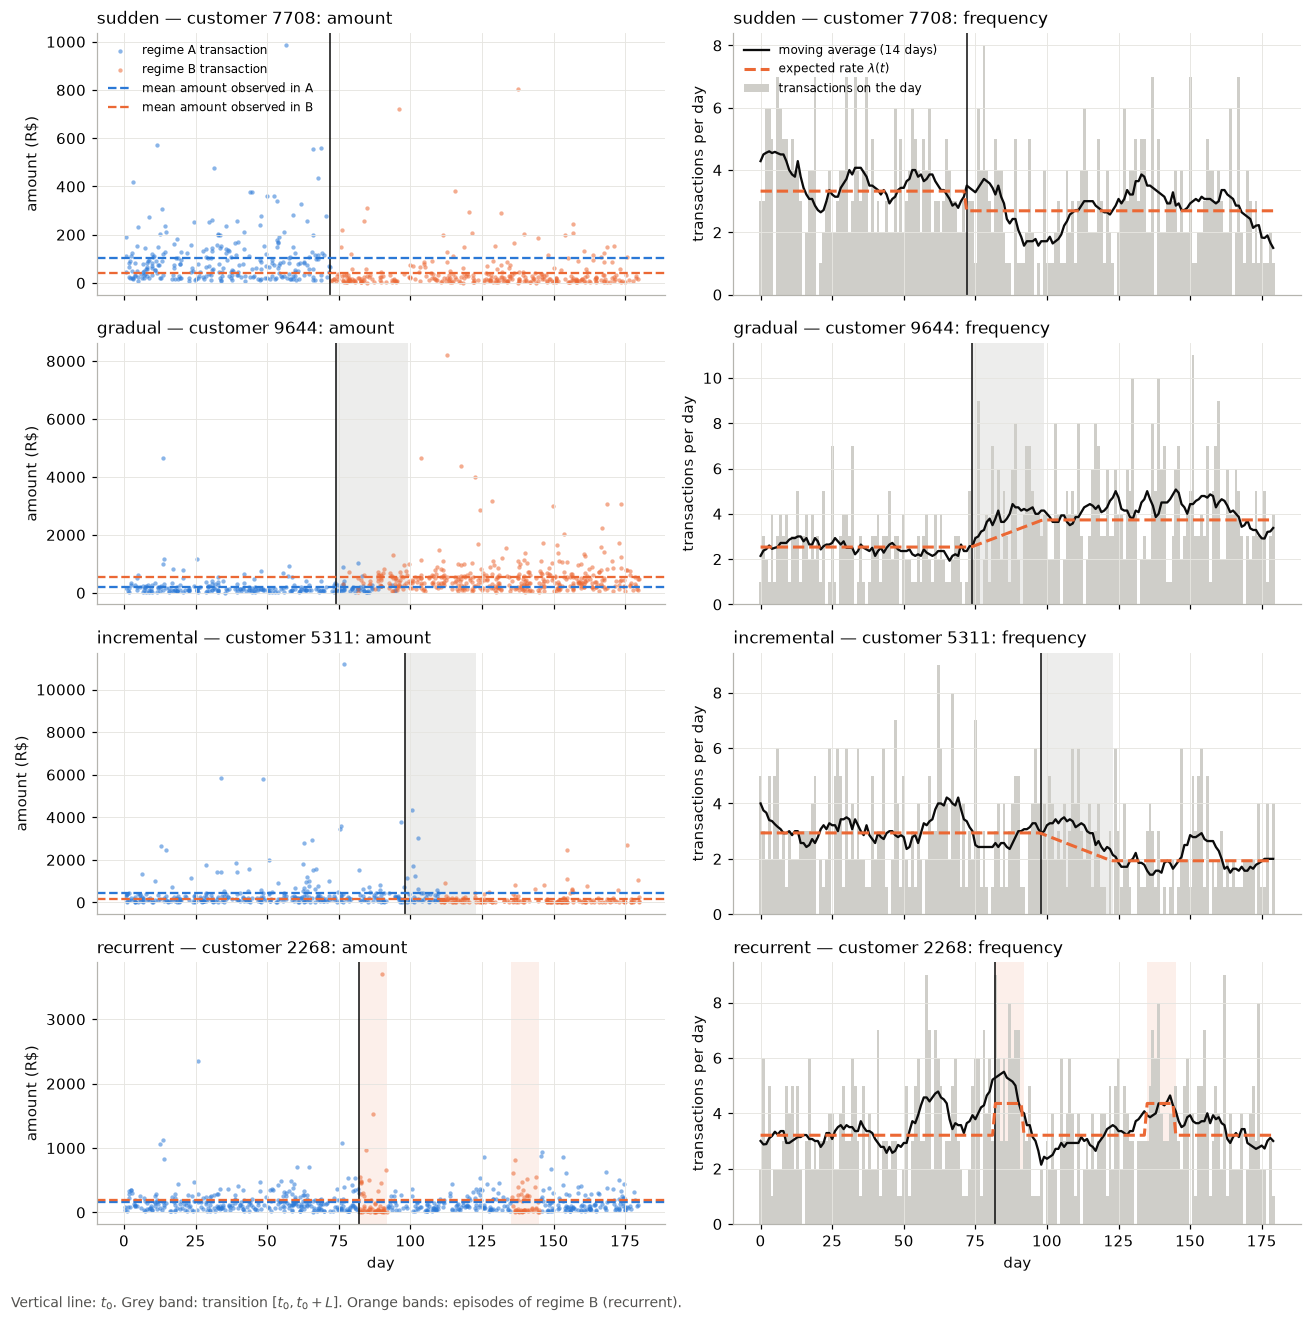

In [4]:
days = np.arange(NB_DAYS)
fig, axes = plt.subplots(4, 2, figsize=(12, 12), sharex=True)

for (kind, row), (ax_amount, ax_count) in zip(examples.items(), axes):
    own = legit[legit.CUSTOMER_ID == row.CUSTOMER_ID]
    w = regime_weight(as_drift(row), days + 0.5)

    # Marks: t0 and the transition (gradual, incremental) or the B episodes (recurrent)
    for ax in (ax_amount, ax_count):
        if kind == "recurrent":
            active = w > 0
            starts = days[active & ~np.r_[False, active[:-1]]]
            ends = days[active & ~np.r_[active[1:], False]] + 1
            for s, e in zip(starts, ends):
                ax.axvspan(s, e, color=COLOR_B, alpha=0.10, lw=0)
        elif kind in ("gradual", "incremental"):
            ax.axvspan(row.GT_DRIFT_T0, row.GT_DRIFT_T0 + row.GT_DRIFT_L, color=MUTED, alpha=0.15, lw=0)
        ax.axvline(row.GT_DRIFT_T0, color=INK, lw=1.0, ls="-")

    for regime, color in (("A", COLOR_A), ("B", COLOR_B)):
        part = own[own.GT_REGIME == regime]
        ax_amount.scatter(part.TX_TIME_SECONDS / 86400, part.TX_AMOUNT, s=8, color=color,
                          alpha=0.55, lw=0, label=T["regime_tx"].format(regime=regime))
    for regime, color in (("A", COLOR_A), ("B", COLOR_B)):
        mean = own.loc[own.GT_REGIME == regime, "TX_AMOUNT"].mean()
        ax_amount.axhline(mean, color=color, lw=1.5, ls="--", label=T["regime_mean"].format(regime=regime))
    ax_amount.set_ylabel(T["amount"])
    ax_amount.set_title(T["amount_title"].format(kind=TYPE_NAMES[kind], customer=row.CUSTOMER_ID), loc="left", fontsize=11)

    per_day = own.groupby("TX_TIME_DAYS").size().reindex(days, fill_value=0)
    expected = (1 - w) * row.mean_nb_tx_per_day + w * row.GT_B_mean_nb_tx_per_day
    ax_count.bar(days, per_day, width=1.0, color="#cfcec9", lw=0, label=T["tx_per_day_bar"])
    ax_count.plot(days, per_day.rolling(14, center=True, min_periods=1).mean(), color=INK, lw=1.5,
                  label=T["rolling_mean"])
    ax_count.plot(days, expected, color=COLOR_B, lw=2, ls="--", label=T["expected_rate"])
    ax_count.set_ylabel(T["tx_per_day"])
    ax_count.set_title(T["frequency_title"].format(kind=TYPE_NAMES[kind], customer=row.CUSTOMER_ID), loc="left", fontsize=11)

for ax in axes[-1]:
    ax.set_xlabel(T["day"])
axes[0, 0].legend(loc="upper left", fontsize=8, frameon=False)
axes[0, 1].legend(loc="upper left", fontsize=8, frameon=False)
fig.text(0.01, 0.005, T["marks_note"], fontsize=9, color="#52514e")
fig.tight_layout(rect=(0, 0.02, 1, 1))
localize(fig)
fig.savefig(FIG_DIR / "drift_customer_examples.pdf", bbox_inches="tight")
plt.show()

## Share in B over time

Mean weight of regime B, $\bar w(t)$, among the customers of each type and among all the
customers (including those without drift). In the sudden and recurrent types,
$w \in \{0, 1\}$ and $\bar w(t)$ is the share of customers in B.

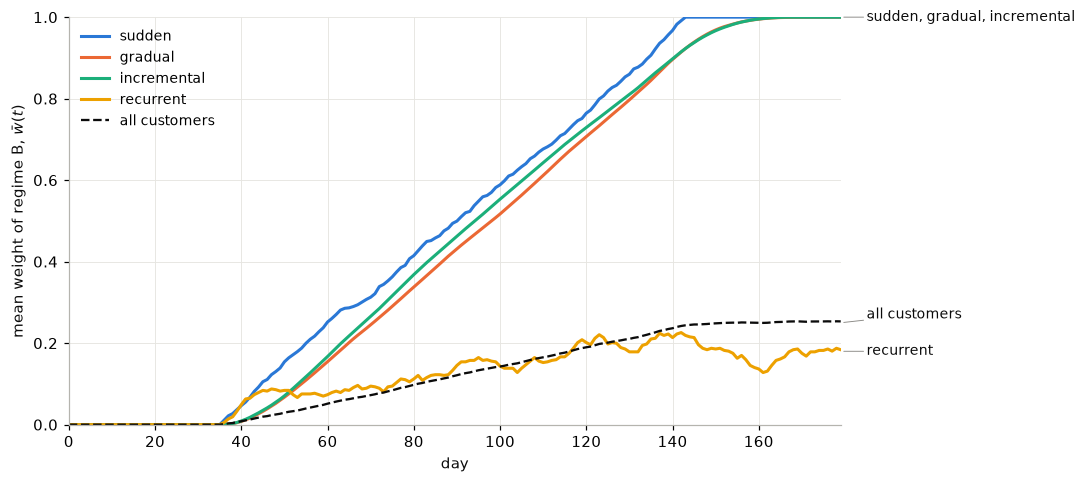

In [5]:
weights = np.vstack([regime_weight(as_drift(row), days + 0.5) for _, row in customers.iterrows()])
kinds = customers.GT_DRIFT_TYPE.to_numpy()

fig, ax = plt.subplots(figsize=(10, 4.5))
ends = {}
for kind, color in TYPE_COLORS.items():
    share = weights[kinds == kind].mean(axis=0)
    ax.plot(days, share, color=color, lw=2, label=TYPE_NAMES[kind])
    ends.setdefault(round(share[-1], 2), []).append(TYPE_NAMES[kind])
overall = weights.mean(axis=0)
ax.plot(days, overall, color=INK, lw=1.5, ls="--", label=T["all_customers"])
ends.setdefault(round(overall[-1], 2), []).append(T["all_customers"])
# Direct labels just right of the plot; lines ending at the same value share one label,
# and labels closer than GAP are pushed up so they do not overlap
GAP = 0.09
placed = []
for value, names in sorted(ends.items()):
    y = max([value] + [p + GAP for p in placed if p > value - GAP])
    placed.append(y)
    ax.annotate(", ".join(names), (days[-1], value), xytext=(days[-1] + 6, y), textcoords="data",
                va="center", fontsize=9, color=INK, annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6, shrinkA=0, shrinkB=2))
ax.set_xlim(0, NB_DAYS - 1)
ax.set_ylim(0, 1)
ax.set_xlabel(T["day"])
ax.set_ylabel(T["mean_weight"])
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
localize(fig)
fig.savefig(FIG_DIR / "drift_regime_b_share.pdf", bbox_inches="tight")
plt.show()

## How much regime B differs from A

Distribution of the changes drawn for the customers with drift: ratio between the amounts
(spending factor, with merchants) and between the frequencies (log scale), and difference
in the CNP probability.

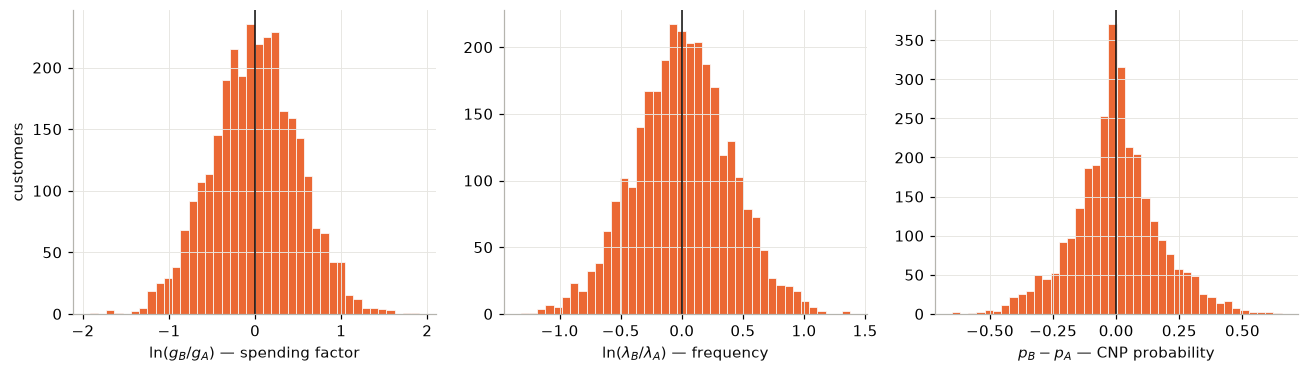

,customers,relocated,mean_log_amount_change
GT_DRIFT_TYPE,,,
gradual,894,43,0.398738
incremental,614,27,0.415483
recurrent,571,23,0.412107
sudden,921,48,0.388065


In [6]:
drifting = customers[customers.GT_DRIFT_TYPE != "none"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
series = [
    (np.log(AMOUNT_RATIO[drifting.index]),
     T["log_spending"] if WITH_MERCHANTS else T["log_amount"]),
    (np.log(drifting.GT_B_mean_nb_tx_per_day / drifting.mean_nb_tx_per_day), T["log_frequency"]),
    (drifting.GT_B_cnp_prob - drifting.cnp_prob, T["cnp_change"]),
]
for ax, (values, label) in zip(axes, series):
    ax.hist(values, bins=40, color=COLOR_B, edgecolor="#fcfcfb", linewidth=0.5)
    ax.axvline(0, color=INK, lw=1)
    ax.set_xlabel(label)
axes[0].set_ylabel(T["customers"])
fig.tight_layout()
localize(fig)
fig.savefig(FIG_DIR / "drift_regime_b_parameters.pdf", bbox_inches="tight")
plt.show()

summary = drifting.assign(
    amount_change=np.abs(np.log(AMOUNT_RATIO[drifting.index])),
).groupby("GT_DRIFT_TYPE").agg(customers=("CUSTOMER_ID", "size"), relocated=("GT_RELOCATED", "sum"),
                                 mean_log_amount_change=("amount_change", "mean"))
summary

## View by category (with merchants)

With merchants (`MerchantConfig`), regime B also changes the **category preferences**:
$\text{pref}_B = (1 - s)\,\text{pref}_A + s\,\text{new}$, with
$s \sim \mathcal{U}(0.3, 0.8)$ and $\text{new}$ drawn like a new customer's preferences
(`category_shift_range`), and spending becomes a factor of the customer, multiplied by the
amount factor of the drift. It uses the same data (`presets.realistic()` has merchants;
with a preset without merchants, the notebook generates the same customers with them).

In [7]:
if WITH_MERCHANTS:
    shop_customers, shop_tx = customers, legit
else:
    shop_customers, _, shop_tx = DatasetGenerator(
        **{**PARAMS, "merchants": MerchantConfig()}
    ).generate()
    shop_tx = shop_tx[shop_tx.TX_FRAUD == 0]
CATEGORY_NAMES = list((PARAMS.get("merchants") or MerchantConfig()).names)
pref_a = shop_customers[[f"pref_{n}" for n in CATEGORY_NAMES]].to_numpy()
pref_b = shop_customers[[f"GT_B_pref_{n}" for n in CATEGORY_NAMES]].to_numpy()
drifting_shop = shop_customers.GT_DRIFT_TYPE != "none"
configured_tvd = 0.5 * np.abs(pref_b - pref_a).sum(axis=1)[drifting_shop.to_numpy()]

# Observed category shares of each drifting customer in each regime
shares = (shop_tx[shop_tx.CUSTOMER_ID.isin(shop_customers.CUSTOMER_ID[drifting_shop])]
          .groupby(["CUSTOMER_ID", "GT_REGIME"]).MERCHANT_CATEGORY.value_counts(normalize=True)
          .unstack(fill_value=0.0).reindex(columns=CATEGORY_NAMES, fill_value=0.0))
both = shares.index.get_level_values(0).value_counts()
both = both[both == 2].index
observed_tvd = 0.5 * (shares.xs("B", level=1).loc[both] - shares.xs("A", level=1).loc[both]).abs().sum(axis=1)
print(f"total variation distance between the preferences of A and B: mean {configured_tvd.mean():.2f} "
      f"(configured) and {observed_tvd.mean():.2f} (observed, {len(both)} customers with purchases in both regimes)")

total variation distance between the preferences of A and B: mean 0.24 (configured) and 0.30 (observed, 2980 customers with purchases in both regimes)


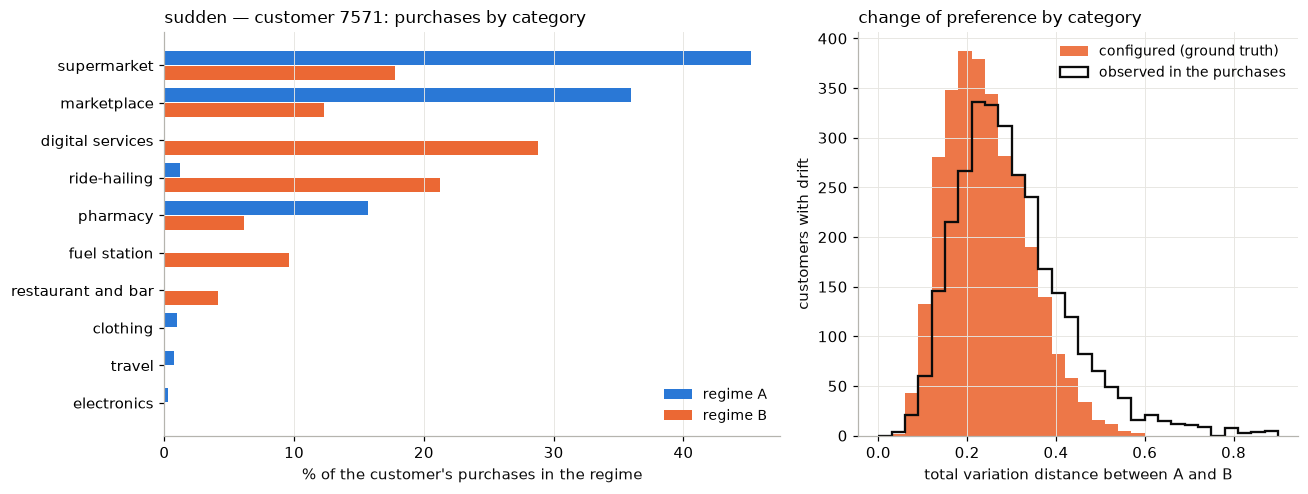

In [8]:
# Example: a frequent sudden customer with a large change of preferences
sudden_ids = shop_customers.index[(shop_customers.GT_DRIFT_TYPE == "sudden")
                                  & (shop_customers.mean_nb_tx_per_day >= 2.5)]
tvd = pd.Series(0.5 * np.abs(pref_b - pref_a).sum(axis=1), index=shop_customers.index)
example = tvd.loc[sudden_ids].idxmax()
example_shares = shares.loc[example].T  # categories x regimes

fig, (ax_example, ax_hist) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
order = example_shares.max(axis=1).sort_values().index
y = np.arange(len(order))
ax_example.barh(y + 0.2, 100 * example_shares.loc[order, "A"], height=0.38, color=COLOR_A, label=T["regime_a"])
ax_example.barh(y - 0.2, 100 * example_shares.loc[order, "B"], height=0.38, color=COLOR_B, label=T["regime_b"])
ax_example.set_yticks(y, [T["categories"].get(name, name) for name in order])
ax_example.set_xlabel(T["share_of_purchases"])
ax_example.set_title(T["category_title"].format(kind=TYPE_NAMES["sudden"], customer=example), loc="left", fontsize=11)
ax_example.legend(loc="lower right", frameon=False, fontsize=9)
ax_example.grid(axis="y", visible=False)

bins = np.linspace(0, 0.9, 31)
ax_hist.hist(configured_tvd, bins=bins, color=COLOR_B, alpha=0.9, label=T["configured"])
ax_hist.hist(observed_tvd, bins=bins, histtype="step", color=INK, lw=1.5, label=T["observed"])
ax_hist.set_xlabel(T["tvd"])
ax_hist.set_ylabel(T["drifting_customers"])
ax_hist.legend(loc="upper right", frameon=False, fontsize=9)
ax_hist.set_title(T["preference_change"], loc="left", fontsize=11)
fig.tight_layout()
localize(fig)
fig.savefig(FIG_DIR / "drift_categories.pdf", bbox_inches="tight")
plt.show()